# IE0005 Mini Project: Netflix Age-Rating Groups

**Research question:** How well can genre and description predict a Netflix title's
age-rating group?

**Inputs:** `listed_in` (genre) and `description`. **Target:** Kids, Teen or Adult,
derived from `rating` using the mapping already used in `IE0005.ipynb`.
These are simplified project labels, not official equivalent ratings.

Run all cells in order with `netflix_titles.csv` beside this notebook. The notebook
creates `course_project_outputs/` with a cleaned dataset, exclusion log, split
assignments, model results, predictions and figures. The original CSV is read only.
The separate `IE0005_Project_Presentation.pptx` summarizes this saved run.

The project demonstrates data acquisition, exploration, preparation, classification,
evaluation and a prediction example. It does not establish a title's official rating.

## Where the code comes from

The short cells, comments, `pd.DataFrame(...)`, `sb` alias, train/test naming, and
`fit` / `predict` / `score` sequence follow the supplied teaching notebooks.
Cell numbers below are **1-based notebook cell positions**, including markdown.

| Source | Patterns adapted here |
|---|---|
| M1 DataAcquisition, cells 2, 5, 13–14 | Imports, dictionaries, CSV loading, DataFrame inspection |
| M2 BasicStatistics, cells 12–22, 32, 34–39 | `describe`, boxplots, histograms, concatenation and correlations |
| M2 ExploratoryAnalysis, cells 12–26, 41–59 | Counts, category plots, groupby heatmaps, duplicates, copies, missing values and text cleaning |
| M4 ClassificationTree, cells 40, 44–46, 56–60, 71–76 | Response/predictor extraction, random splitting, decision tree, accuracy, confusion matrices and prediction demonstration |
| M5 ClusteringPatterns, cells 11–28 | Optional KMeans investigation of description format |
| M5 DetectingAnomalies, cells 11–18 | Optional LocalOutlierFactor flags for inspection |

No M3 file was supplied. The two M1 copies contain the same example code.

### Highlighted additions beyond the supplied examples

**PROJECT ADAPTATION (P):** Netflix-specific cleaning rules, rating mapping, string
splitting, group-safe split assembly and a majority-class baseline are new project
logic written using the same pandas/NumPy style. They are not copied from a course cell.

**EXTENSION E1 — text features:** `CountVectorizer`, `fit_transform`, `transform` and
`get_feature_names_out`. Needed because the course models use numeric predictors.
[Official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html).

**EXTENSION E2 — Naive Bayes:** `MultinomialNB`. Required by the project notes but
absent from the supplied teaching notebooks.
[Official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html).

**EXTENSION E3 — evaluation:** `f1_score` and `classification_report` extend M4's
accuracy/confusion-matrix evaluation to imbalanced classes.
[F1 documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
and [classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).

**EXTENSION E4 — reproducibility and export:** `Path`, CSV/figure/JSON export,
assertions and package-version recording. These support the submission rather
than introduce another model. `random_state` and `stratify` extend the M4 split
example; see [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

All additions are marked at the relevant cells. They were written for this project;
official API documentation was consulted, not an external project solution.

## 1. Acquire and inspect the dataset

**Course basis: M1 and M2.**

In [1]:
# Basic Libraries -- same style as M1, M2, M4 and M5
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import re
sb.set()

# EXTENSION E4: output folder and reproducible environment information
from pathlib import Path
import json
import sys
import sklearn
import matplotlib

output_folder = Path("course_project_outputs")
output_folder.mkdir(exist_ok = True)
random_seed = 42
class_order = ["Kids", "Teen", "Adult"]

print("Python version :", sys.version.split()[0])
print("NumPy version :", np.__version__)
print("pandas version :", pd.__version__)
print("scikit-learn version :", sklearn.__version__)

Python version : 3.12.10
NumPy version : 2.5.4
pandas version : 3.0.6
scikit-learn version : 1.9.1


In [2]:
# Read the dataset -- M1
netflix_data = pd.read_csv("netflix_titles.csv")
print("Data type :", type(netflix_data))
print("Data dims :", netflix_data.shape)
netflix_data.head()

Data type : <class 'pandas.DataFrame'>
Data dims : (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Check variable types and missing values -- M2
netflix_data.info()
print("\nMissing values in the three project variables")
print(netflix_data[["listed_in", "description", "rating"]].isnull().sum())
print("\nDuplicate complete rows :", netflix_data.duplicated().sum())

variable_details = pd.DataFrame({
    "CSV variable" : ["listed_in", "description", "rating"],
    "Meaning" : ["Genre/category labels", "Short title synopsis", "Recorded audience rating"],
    "Data type" : ["Multiple categorical labels", "Free text", "Categorical label"],
    "Role" : ["Predictor", "Predictor", "Source of target"]
})
variable_details

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

Missing values in the three project variables
listed_in      0
description    0
rating         4
dtype: int64

Duplicate complete rows : 0


,CSV variable,Meaning,Data type,Role
0,listed_in,Genre/category labels,Multiple categorical labels,Predictor
1,description,Short title synopsis,Free text,Predictor
2,rating,Recorded audience rating,Categorical label,Source of target


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


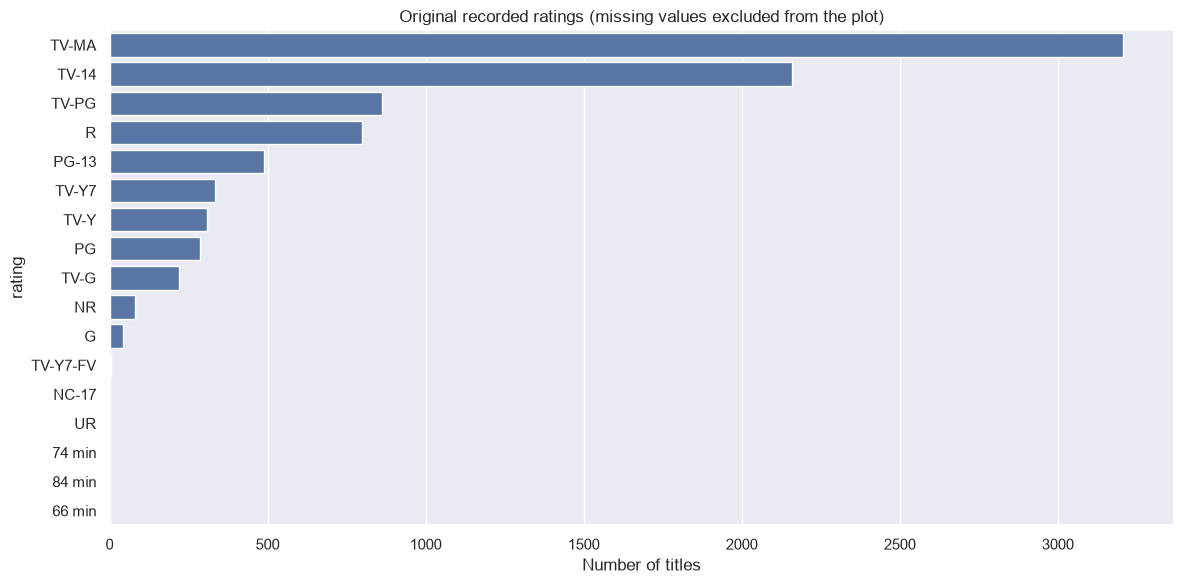

In [4]:
# Count the original ratings, including missing values -- M2
print(netflix_data["rating"].value_counts(dropna = False))
f = plt.figure(figsize = (12, 6))
sb.countplot(y = "rating", data = netflix_data,
             order = netflix_data["rating"].value_counts().index)
plt.title("Original recorded ratings (missing values excluded from the plot)")
plt.xlabel("Number of titles")
plt.tight_layout()
# EXTENSION E4: save a figure for the presentation
plt.savefig(output_folder / "01_original_ratings.png", dpi = 150)
plt.show()

## 2. Clean and prepare a suitable dataset

**Course basis: M2 copies, renaming, missing-value checks, filtering and duplicates.**
**P:** The rules below are project decisions:

1. Keep title identifiers for inspection; only genre and description are predictors.
2. Standardize whitespace, retain the original meaningful text, and convert blank strings to missing.
3. Exclude missing predictors, missing ratings, `NR`/`UR`, and unexpected ratings.
   Values such as `74 min` are not guessed or replaced with an age rating.
4. Keep one row per `show_id`; record every excluded row and its first exclusion reason.
5. Keep distinct titles with repeated descriptions, but keep matching descriptions
   in the same train/validation/test partition.

Do not drop rows because unrelated fields such as director or country are missing.
The raw CSV remains the source for rerunning these decisions.

In [5]:
# Extract only the relevant variables -- M2
netflix_clean = pd.DataFrame(netflix_data[
    ["show_id", "title", "listed_in", "description", "rating"]]).copy()
netflix_clean.rename(columns = {
    "show_id" : "ShowID", "title" : "Title", "listed_in" : "Genre",
    "description" : "Description", "rating" : "Rating"
}, inplace = True)

# P: adapt M2's re.sub text-cleaning pattern to Netflix text
for var in ["Genre", "Description", "Rating"]:
    netflix_clean[var] = netflix_clean[var].apply(
        lambda x: re.sub(r"\s+", " ", x).strip() if isinstance(x, str) else x)
    netflix_clean.loc[netflix_clean[var] == "", var] = np.nan

# P: remove spaces around comma-separated genre labels
netflix_clean["Genre"] = netflix_clean["Genre"].apply(
    lambda x: ", ".join(sorted(set(g.strip() for g in x.split(",") if g.strip())))
    if isinstance(x, str) else x)
netflix_clean.loc[netflix_clean["Genre"] == "", "Genre"] = np.nan
netflix_clean.head()

,ShowID,Title,Genre,Description,Rating
0,s1,Dick Johnson Is Dead,Documentaries,"As her father nears the end of his life, filmm...",PG-13
1,s2,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",TV-MA
2,s3,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,TV-MA
3,s4,Jailbirds New Orleans,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",TV-MA
4,s5,Kota Factory,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,TV-MA


In [6]:
# P: preserve the grouping already used in IE0005.ipynb
rating_groups = {
    "TV-Y" : "Kids", "TV-Y7" : "Kids", "TV-Y7-FV" : "Kids",
    "TV-G" : "Kids", "G" : "Kids",
    "PG" : "Teen", "TV-PG" : "Teen", "PG-13" : "Teen", "TV-14" : "Teen",
    "R" : "Adult", "TV-MA" : "Adult", "NC-17" : "Adult"
}
pd.DataFrame(list(rating_groups.items()), columns = ["Original rating", "Project group"])

,Original rating,Project group
0,TV-Y,Kids
1,TV-Y7,Kids
2,TV-Y7-FV,Kids
3,TV-G,Kids
4,G,Kids
5,PG,Teen
6,TV-PG,Teen
7,PG-13,Teen
8,TV-14,Teen
9,R,Adult


**Mapping limitation:** Kids/Teen/Adult are convenient project groups. For example,
assigning `PG` and `TV-PG` to Teen is a simplification, not an official equivalence.
The original `Rating` column is retained so the mapping can be revised. Results
below evaluate these three groups, not exact original ratings.

In [7]:
# P: record the FIRST applicable exclusion reason for every removed row
exclusion_reason = pd.Series("", index = netflix_clean.index, dtype = "object")
exclusion_reason.loc[netflix_clean["ShowID"].isnull()] = "Missing title ID"
exclusion_reason.loc[(exclusion_reason == "") &
    netflix_clean[["Genre", "Description"]].isnull().any(axis = 1)] = "Missing genre or description"
exclusion_reason.loc[(exclusion_reason == "") &
    netflix_clean["Rating"].isnull()] = "Missing rating"
exclusion_reason.loc[(exclusion_reason == "") &
    netflix_clean["Rating"].isin(["NR", "UR"])] = "Unrated label"
exclusion_reason.loc[(exclusion_reason == "") &
    ~netflix_clean["Rating"].isin(rating_groups)] = "Unexpected rating"

# M2 duplicate-check pattern, applied after validity checks
eligible = netflix_clean.loc[exclusion_reason == ""]
duplicate_ids = eligible.index[eligible.duplicated("ShowID")]
exclusion_reason.loc[duplicate_ids] = "Repeated title ID"

excluded_data = netflix_clean.loc[exclusion_reason != ""].copy()
excluded_data["ExclusionReason"] = exclusion_reason.loc[exclusion_reason != ""]
netflix_clean = netflix_clean.loc[exclusion_reason == ""].copy()
netflix_clean["RatingGroup"] = netflix_clean["Rating"].map(rating_groups)

# P: a normalized description key prevents repeated text crossing data splits
netflix_clean["DescriptionKey"] = netflix_clean["Description"].str.lower()
netflix_clean["WordCount"] = netflix_clean["Description"].str.split().str.len()
netflix_clean["CharacterCount"] = netflix_clean["Description"].str.len()
netflix_clean["GenreCount"] = netflix_clean["Genre"].str.split(",").str.len()

print("Original rows :", len(netflix_data))
print("Excluded rows :", len(excluded_data))
print("Clean rows :", len(netflix_clean))
print("\nExclusions by reason")
print(excluded_data["ExclusionReason"].value_counts())
print("\nRemaining missing values")
print(netflix_clean.isnull().sum())

# EXTENSION E4: checks and exports
assert len(netflix_clean) + len(excluded_data) == len(netflix_data)
assert netflix_clean[["Genre", "Description", "RatingGroup"]].notna().all().all()
assert netflix_clean["ShowID"].is_unique
netflix_clean.to_csv(output_folder / "netflix_clean.csv", index = False)
excluded_data.to_csv(output_folder / "excluded_rows.csv", index = False)
cleaning_summary = pd.DataFrame({
    "Stage" : ["Original", "Excluded", "Clean"],
    "Rows" : [len(netflix_data), len(excluded_data), len(netflix_clean)]
})
cleaning_summary.to_csv(output_folder / "cleaning_summary.csv", index = False)
netflix_clean.head()

Original rows : 8807
Excluded rows : 90
Clean rows : 8717

Exclusions by reason
ExclusionReason
Unrated label        83
Missing rating        4
Unexpected rating     3
Name: count, dtype: int64

Remaining missing values
ShowID            0
Title             0
Genre             0
Description       0
Rating            0
RatingGroup       0
DescriptionKey    0
WordCount         0
CharacterCount    0
GenreCount        0
dtype: int64


,ShowID,Title,Genre,Description,Rating,RatingGroup,DescriptionKey,WordCount,CharacterCount,GenreCount
0,s1,Dick Johnson Is Dead,Documentaries,"As her father nears the end of his life, filmm...",PG-13,Teen,"as her father nears the end of his life, filmm...",27,152,1
1,s2,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",TV-MA,Adult,"after crossing paths at a party, a cape town t...",27,147,3
2,s3,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,TV-MA,Adult,to protect his family from a powerful drug lor...,27,146,3
3,s4,Jailbirds New Orleans,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",TV-MA,Adult,"feuds, flirtations and toilet talk go down amo...",24,147,2
4,s5,Kota Factory,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,TV-MA,Adult,in a city of coaching centers known to train i...,24,152,3


## 3. Reserve validation and test sets before modelling

**Course basis: M4 `train_test_split`, now with fixed randomness and stratification.**
**P:** Split *unique normalized descriptions* first, then select all corresponding
titles. Approximately 60% of description groups are used for training, 20% for
validation, and 20% for testing. Row percentages may differ slightly.

Some repeated descriptions belong to titles with different ratings. All are kept;
the first title's group is used only as a stratification label for assigning the
description group. Original per-title targets remain unchanged. Exact text matches
cannot cross partitions, although near-duplicates and franchise relationships may remain.

Use validation to choose a model. Keep the test set reserved for the final,
predeclared comparison. The detailed exploratory plots below use training rows.

In [8]:
# M4: train_test_split; P: split description groups rather than individual rows
from sklearn.model_selection import train_test_split

split_groups = netflix_clean.loc[
    ~netflix_clean.duplicated("DescriptionKey"), ["DescriptionKey", "RatingGroup"]]
train_groups, holdout_groups = train_test_split(
    split_groups, test_size = 0.40, random_state = random_seed,
    stratify = split_groups["RatingGroup"])
valid_groups, test_groups = train_test_split(
    holdout_groups, test_size = 0.50, random_state = random_seed,
    stratify = holdout_groups["RatingGroup"])

train_data = netflix_clean[netflix_clean["DescriptionKey"].isin(train_groups["DescriptionKey"])].copy()
valid_data = netflix_clean[netflix_clean["DescriptionKey"].isin(valid_groups["DescriptionKey"])].copy()
test_data = netflix_clean[netflix_clean["DescriptionKey"].isin(test_groups["DescriptionKey"])].copy()

print("Train Set :", train_data.shape)
print("Validation Set :", valid_data.shape)
print("Test Set :", test_data.shape)
print("Repeated description rows :", netflix_clean.duplicated("DescriptionKey").sum())
print("Description groups with different target labels :",
      (netflix_clean.groupby("DescriptionKey")["RatingGroup"].nunique() > 1).sum())

split_summary = pd.DataFrame({
    "Train" : train_data["RatingGroup"].value_counts(),
    "Validation" : valid_data["RatingGroup"].value_counts(),
    "Test" : test_data["RatingGroup"].value_counts()
}).reindex(class_order)

# EXTENSION E4: verify separation and preserve split assignments
assert set(train_data["DescriptionKey"]).isdisjoint(valid_data["DescriptionKey"])
assert set(train_data["DescriptionKey"]).isdisjoint(test_data["DescriptionKey"])
assert set(valid_data["DescriptionKey"]).isdisjoint(test_data["DescriptionKey"])
assert len(train_data) + len(valid_data) + len(test_data) == len(netflix_clean)
assert (split_summary > 0).all().all()
split_assignments = pd.concat([
    train_data[["ShowID"]].assign(Split = "Train"),
    valid_data[["ShowID"]].assign(Split = "Validation"),
    test_data[["ShowID"]].assign(Split = "Test")
])
split_assignments.to_csv(output_folder / "split_assignments.csv", index = False)
split_summary.to_csv(output_folder / "split_summary.csv")
split_summary

Train Set : (5233, 10)
Validation Set : (1740, 10)
Test Set : (1744, 10)
Repeated description rows : 31
Description groups with different target labels : 2


,Train,Validation,Test
RatingGroup,,,
Kids,545,181,182
Teen,2283,758,759
Adult,2405,801,803


## 4. Explore relevant training-data patterns

**Course basis: M2 count plots, summary statistics, histograms, boxplots and groupby
heatmaps.** These plots describe the three predictors/target variables and reveal
class imbalance. Genre and description are inputs; word/character counts are
derived summaries rather than additional source variables.

RatingGroup
Kids      545
Teen     2283
Adult    2405
Name: count, dtype: int64


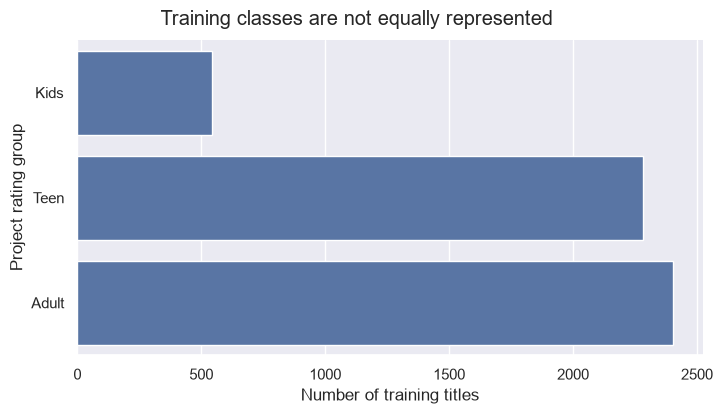

Largest training class share : 45.96 %


In [9]:
# M2: response distribution
print(train_data["RatingGroup"].value_counts().reindex(class_order))
g = sb.catplot(y = "RatingGroup", data = train_data, kind = "count",
               order = class_order, height = 4, aspect = 1.8)
g.set_axis_labels("Number of training titles", "Project rating group")
g.fig.suptitle("Training classes are not equally represented", y = 1.03)
g.fig.savefig(output_folder / "02_training_groups.png", dpi = 150, bbox_inches = "tight")
plt.show()

majority_share = train_data["RatingGroup"].value_counts().iloc[0] / len(train_data)
print("Largest training class share :", round(100 * majority_share, 2), "%")

Genre
International Movies        1608
Dramas                      1450
Comedies                     985
International TV Shows       803
Action & Adventure           529
Documentaries                478
TV Dramas                    465
Independent Movies           437
Children & Family Movies     383
Romantic Movies              373
Name: count, dtype: int64


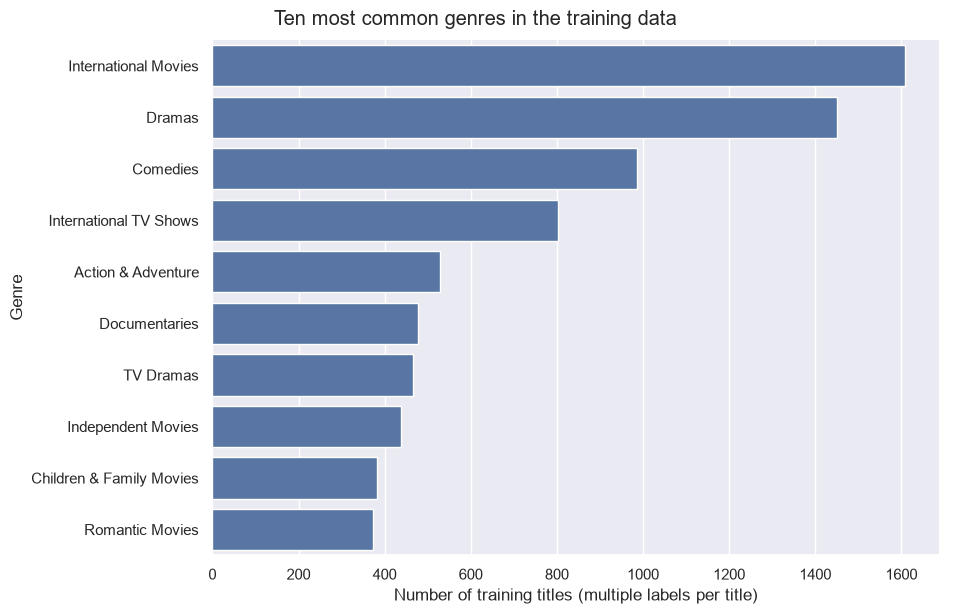

In [10]:
# P: count complete individual genre labels, using M2 value_counts and category plots
genre_rows = train_data[["Genre", "RatingGroup"]].copy()
genre_rows["Genre"] = genre_rows["Genre"].str.split(", ")
genre_rows = genre_rows.explode("Genre", ignore_index = True)
top_genres = genre_rows["Genre"].value_counts().head(10)
print(top_genres)
g = sb.catplot(y = "Genre", data = genre_rows, kind = "count",
               order = top_genres.index, height = 6, aspect = 1.6)
g.set_axis_labels("Number of training titles (multiple labels per title)", "Genre")
g.fig.suptitle("Ten most common genres in the training data", y = 1.02)
g.fig.savefig(output_folder / "03_training_genres.png", dpi = 150, bbox_inches = "tight")
plt.show()

       WordCount  CharacterCount  GenreCount
count    5233.00         5233.00     5233.00
mean       23.86          143.24        2.20
std         2.78            9.96        0.78
min        10.00           61.00        1.00
25%        22.00          140.00        2.00
50%        24.00          146.00        2.00
75%        26.00          149.00        3.00
max        41.00          246.00        3.00


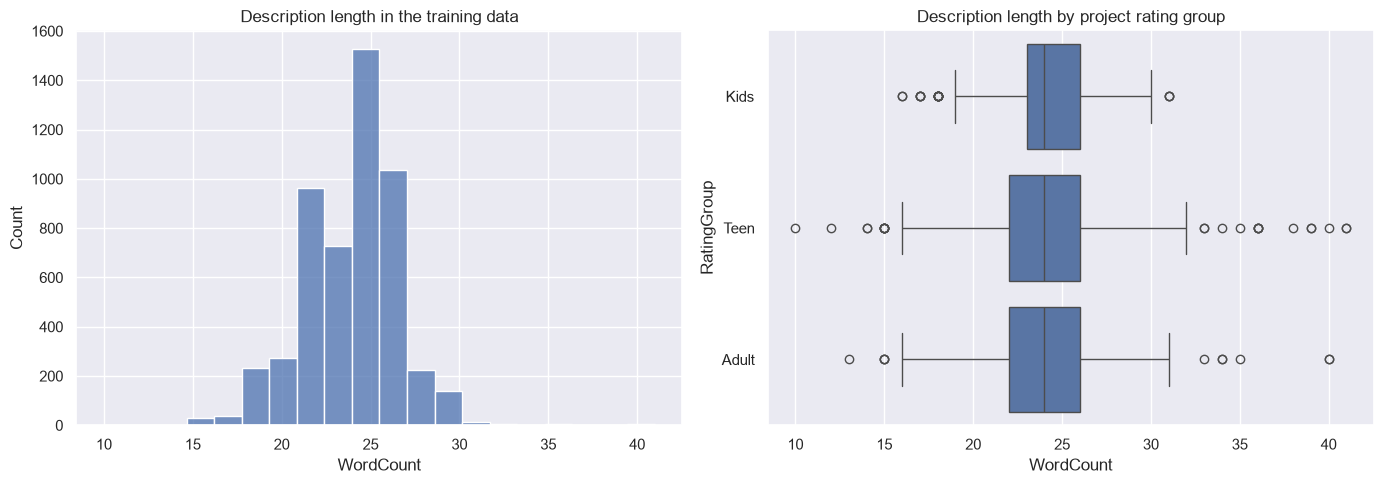

In [11]:
# M2: describe the numeric measurements derived from text
description_stats = train_data[["WordCount", "CharacterCount", "GenreCount"]].describe().round(2)
print(description_stats)
f, axes = plt.subplots(1, 2, figsize = (14, 5))
sb.histplot(data = train_data, x = "WordCount", bins = 20, ax = axes[0])
sb.boxplot(x = "WordCount", y = "RatingGroup", data = train_data,
           order = class_order, orient = "h", ax = axes[1])
axes[0].set_title("Description length in the training data")
axes[1].set_title("Description length by project rating group")
plt.tight_layout()
plt.savefig(output_folder / "04_description_lengths.png", dpi = 150)
plt.show()

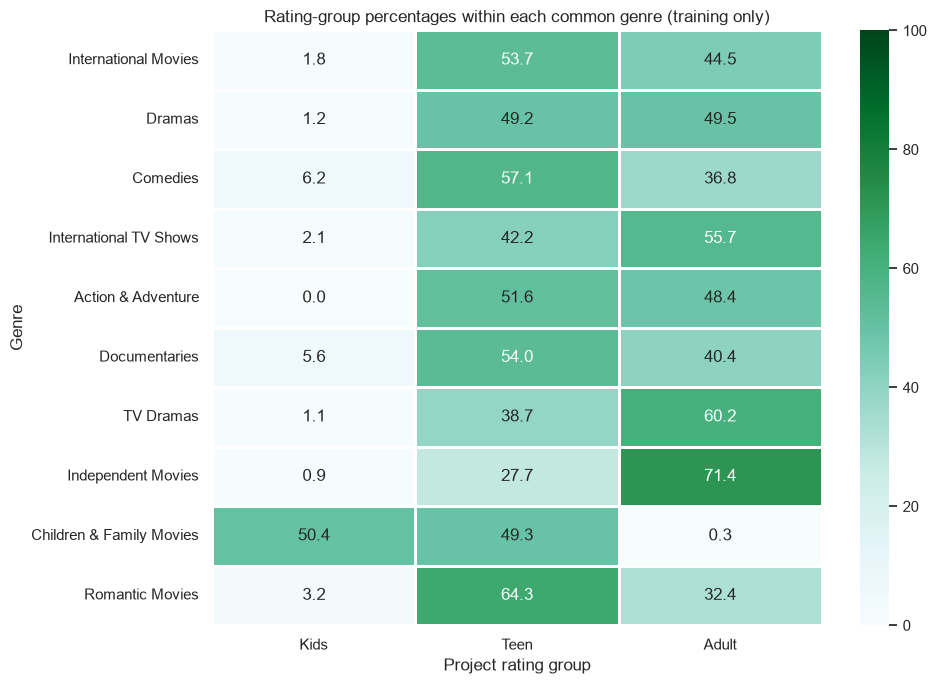

In [12]:
# M2: groupby and unstack heatmap; P: normalize within each genre
genre_groups = genre_rows.groupby(["Genre", "RatingGroup"]).size().unstack(fill_value = 0)
genre_groups = genre_groups.reindex(index = top_genres.index, columns = class_order)
genre_percent = genre_groups.div(genre_groups.sum(axis = 1), axis = 0) * 100

f = plt.figure(figsize = (10, 7))
sb.heatmap(genre_percent, annot = True, fmt = ".1f", cmap = "BuGn",
           vmin = 0, vmax = 100, linewidths = 1)
plt.title("Rating-group percentages within each common genre (training only)")
plt.xlabel("Project rating group")
plt.tight_layout()
plt.savefig(output_folder / "05_genre_group_percentages.png", dpi = 150)
plt.show()
genre_percent.to_csv(output_folder / "genre_group_percentages.csv")

**Interpretation:** compare the class-count chart with the genre heatmap. A majority
class can make accuracy look strong even when smaller classes are missed. The genre
heatmap shows associations with labels; it does not prove causation. Overlapping
description-length distributions suggest length alone may not separate the groups.
The next section uses the actual description words and complete genre labels.

## 5. Convert genre and description into numerical features

**EXTENSION E1 — outside M1–M5:** use `CountVectorizer` for the text inputs.
Genre labels become binary columns; description words become nonnegative count
columns. Full genre labels such as `International Movies` stay together.

Learn both vocabularies from training data only. Validation/test descriptions are
transformed with the learned vocabulary. Limit descriptions to 2,000 terms occurring
in at least three training titles to keep the notebook manageable. These settings
are fixed before evaluation.

The matrices are converted to pandas DataFrames to follow M4's predictor-table style.
This is simple for this dataset, but a larger dataset should retain sparse matrices.

In [13]:
# EXTENSION E1: text features, not present in the supplied M1-M5 examples
from sklearn.feature_extraction.text import CountVectorizer

genre_vectorizer = CountVectorizer(
    tokenizer = lambda text: [genre.strip() for genre in text.split(",")],
    token_pattern = None, lowercase = False, binary = True, dtype = np.int32)
word_vectorizer = CountVectorizer(
    stop_words = "english", min_df = 3, max_features = 2000, dtype = np.int32)

genre_train = genre_vectorizer.fit_transform(train_data["Genre"])
genre_valid = genre_vectorizer.transform(valid_data["Genre"])
word_train = word_vectorizer.fit_transform(train_data["Description"])
word_valid = word_vectorizer.transform(valid_data["Description"])

genre_columns = ["Genre: " + name for name in genre_vectorizer.get_feature_names_out()]
word_columns = ["Word: " + name for name in word_vectorizer.get_feature_names_out()]

# M2/M4: assemble aligned DataFrames and concatenate predictors
X_genre_train = pd.DataFrame(genre_train.toarray(), columns = genre_columns, index = train_data.index)
X_genre_valid = pd.DataFrame(genre_valid.toarray(), columns = genre_columns, index = valid_data.index)
X_word_train = pd.DataFrame(word_train.toarray(), columns = word_columns, index = train_data.index)
X_word_valid = pd.DataFrame(word_valid.toarray(), columns = word_columns, index = valid_data.index)
X_train = pd.concat([X_genre_train, X_word_train], axis = 1)
X_valid = pd.concat([X_genre_valid, X_word_valid], axis = 1)
y_train = train_data["RatingGroup"]
y_valid = valid_data["RatingGroup"]

print("Training predictors :", X_train.shape)
print("Validation predictors :", X_valid.shape)
print("Genre columns :", len(genre_columns))
print("Word columns :", len(word_columns))
assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)
X_train.head()

Training predictors : (5233, 2042)
Validation predictors : (1740, 2042)
Genre columns : 42
Word columns : 2000


,Genre: Action & Adventure,Genre: Anime Features,Genre: Anime Series,Genre: British TV Shows,Genre: Children & Family Movies,Genre: Classic & Cult TV,Genre: Classic Movies,Genre: Comedies,Genre: Crime TV Shows,Genre: Cult Movies,...,Word: written,Word: wrong,Word: year,Word: years,Word: york,Word: young,Word: younger,Word: youth,Word: zany,Word: zombie
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 6. Train a course decision tree and explore Naive Bayes

**M4 reference model:** a decision tree with maximum depth 4.
**EXTENSION E2:** Multinomial Naive Bayes with smoothing `alpha = 1.0`.

Predeclared comparisons:
1. Majority-class baseline (P): always predict the most common training class.
2. M4 decision tree: genre and description.
3. Naive Bayes: genre only.
4. Naive Bayes: description only.
5. Naive Bayes: genre and description.

This is a fixed first experiment, not an exhaustive parameter search. Compare
genre/description/both to see which inputs help. Naive Bayes assumes feature
independence conditional on the class, an approximation for related words/genres.

In [14]:
# M4: create and fit a Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

dectree = DecisionTreeClassifier(max_depth = 4, random_state = random_seed)
dectree.fit(X_train, y_train)
tree_valid_pred = dectree.predict(X_valid)
print("Decision Tree Training Accuracy :", dectree.score(X_train, y_train))
print("Decision Tree Validation Accuracy :", dectree.score(X_valid, y_valid))

Decision Tree Training Accuracy : 0.56315688897382
Decision Tree Validation Accuracy : 0.5603448275862069


In [15]:
# EXTENSION E2: Naive Bayes is required by the project but absent from M1-M5
from sklearn.naive_bayes import MultinomialNB

nb_genre = MultinomialNB(alpha = 1.0)
nb_genre.fit(X_genre_train, y_train)
genre_valid_pred = nb_genre.predict(X_genre_valid)

nb_word = MultinomialNB(alpha = 1.0)
nb_word.fit(X_word_train, y_train)
word_valid_pred = nb_word.predict(X_word_valid)

nb_both = MultinomialNB(alpha = 1.0)
nb_both.fit(X_train, y_train)
both_valid_pred = nb_both.predict(X_valid)

print("Naive Bayes Combined Training Accuracy :", nb_both.score(X_train, y_train))
print("Naive Bayes Combined Validation Accuracy :", nb_both.score(X_valid, y_valid))

Naive Bayes Combined Training Accuracy : 0.7628511370150965
Naive Bayes Combined Validation Accuracy : 0.6626436781609195


In [16]:
# P: majority-class baseline; EXTENSION E3: macro F1
from sklearn.metrics import f1_score, classification_report

majority_class = y_train.value_counts().index[0]
baseline_valid_pred = np.repeat(majority_class, len(y_valid))
validation_predictions = {
    "Majority baseline" : baseline_valid_pred,
    "Decision tree: both" : tree_valid_pred,
    "Naive Bayes: genre" : genre_valid_pred,
    "Naive Bayes: description" : word_valid_pred,
    "Naive Bayes: both" : both_valid_pred
}
validation_rows = []
for name in validation_predictions:
    prediction = validation_predictions[name]
    validation_rows.append({
        "Model" : name,
        "Accuracy" : np.mean(prediction == y_valid),
        "Macro F1" : f1_score(y_valid, prediction, labels = class_order,
                             average = "macro", zero_division = 0)
    })
validation_results = pd.DataFrame(validation_rows).set_index("Model")
selected_model = validation_results["Macro F1"].idxmax()
print("Model selected using validation Macro F1 :", selected_model)
validation_results.to_csv(output_folder / "validation_results.csv")
validation_results.round(4)

Model selected using validation Macro F1 : Naive Bayes: both


,Accuracy,Macro F1
Model,,
Majority baseline,0.4603,0.2102
Decision tree: both,0.5603,0.5752
Naive Bayes: genre,0.6236,0.6617
Naive Bayes: description,0.5908,0.5996
Naive Bayes: both,0.6626,0.6825


Macro F1 averages the three class F1 scores equally, so small classes matter.
Accuracy is still reported, following M4. The selected model is locked using
validation Macro F1 before the test results are calculated. If the baseline wins,
report that outcome honestly.

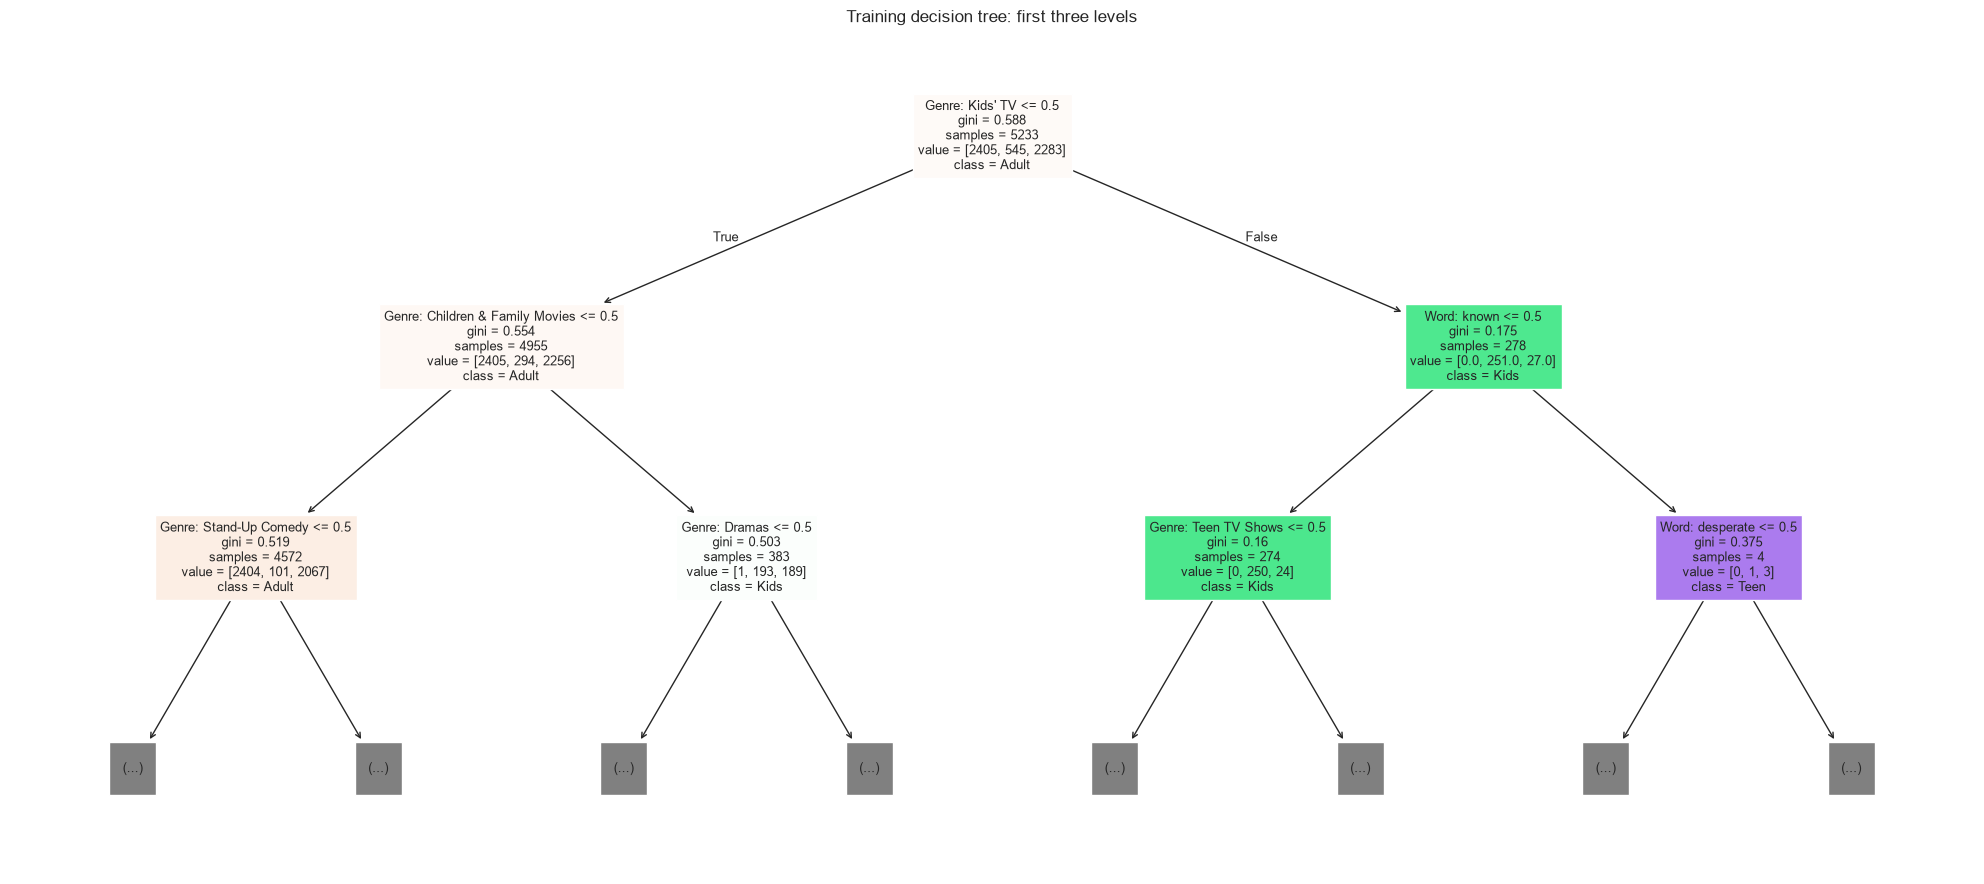

In [17]:
# M4: inspect the decision tree structure (first three levels for readability)
from sklearn.tree import plot_tree
f, ax = plt.subplots(figsize = (20, 9))
plot_tree(dectree, feature_names = X_train.columns.tolist(),
          class_names = [str(x) for x in dectree.classes_],
          filled = True, max_depth = 2, fontsize = 9, ax = ax)
plt.title("Training decision tree: first three levels")
plt.tight_layout()
plt.savefig(output_folder / "06_decision_tree.png", dpi = 150)
plt.show()

## 7. Refit on training + validation, then evaluate once on the test set

Combine the two development partitions, relearn vocabularies using those rows only,
and refit the fixed models. The test set supplies no vocabulary, parameters or model
selection decisions. All five frozen approaches are reported to answer the input
comparison question; the previously selected model remains the chosen model.

In [18]:
# M2: concat; E1: learn final vocabularies from development data only
development_data = pd.concat([train_data, valid_data]).sort_index()
y_development = development_data["RatingGroup"]
y_test = test_data["RatingGroup"]

final_genre_vectorizer = CountVectorizer(
    tokenizer = lambda text: [genre.strip() for genre in text.split(",")],
    token_pattern = None, lowercase = False, binary = True, dtype = np.int32)
final_word_vectorizer = CountVectorizer(
    stop_words = "english", min_df = 3, max_features = 2000, dtype = np.int32)

genre_development = final_genre_vectorizer.fit_transform(development_data["Genre"])
genre_test = final_genre_vectorizer.transform(test_data["Genre"])
word_development = final_word_vectorizer.fit_transform(development_data["Description"])
word_test = final_word_vectorizer.transform(test_data["Description"])
final_genre_columns = ["Genre: " + name for name in final_genre_vectorizer.get_feature_names_out()]
final_word_columns = ["Word: " + name for name in final_word_vectorizer.get_feature_names_out()]

X_genre_development = pd.DataFrame(genre_development.toarray(),
    columns = final_genre_columns, index = development_data.index)
X_genre_test = pd.DataFrame(genre_test.toarray(),
    columns = final_genre_columns, index = test_data.index)
X_word_development = pd.DataFrame(word_development.toarray(),
    columns = final_word_columns, index = development_data.index)
X_word_test = pd.DataFrame(word_test.toarray(),
    columns = final_word_columns, index = test_data.index)
X_development = pd.concat([X_genre_development, X_word_development], axis = 1)
X_test = pd.concat([X_genre_test, X_word_test], axis = 1)

# P / E4: no target or title identifier is supplied as an input feature
assert X_development.columns.equals(X_test.columns)
assert X_test.index.equals(y_test.index)
assert not {"Rating", "RatingGroup", "Title", "ShowID"}.intersection(X_test.columns)
print("Final development set :", X_development.shape)
print("Reserved test set :", X_test.shape)
print("Test titles with no known description words :", (word_test.sum(axis = 1) == 0).sum())

Final development set : (6973, 2042)
Reserved test set : (1744, 2042)
Test titles with no known description words : 0


In [19]:
# M4 fit/predict pattern; E2 Naive Bayes
final_tree = DecisionTreeClassifier(max_depth = 4, random_state = random_seed)
final_tree.fit(X_development, y_development)
final_nb_genre = MultinomialNB(alpha = 1.0)
final_nb_genre.fit(X_genre_development, y_development)
final_nb_word = MultinomialNB(alpha = 1.0)
final_nb_word.fit(X_word_development, y_development)
final_nb_both = MultinomialNB(alpha = 1.0)
final_nb_both.fit(X_development, y_development)

final_majority = y_development.value_counts().index[0]
test_predictions = {
    "Majority baseline" : np.repeat(final_majority, len(y_test)),
    "Decision tree: both" : final_tree.predict(X_test),
    "Naive Bayes: genre" : final_nb_genre.predict(X_genre_test),
    "Naive Bayes: description" : final_nb_word.predict(X_word_test),
    "Naive Bayes: both" : final_nb_both.predict(X_test)
}
test_rows = []
for name in test_predictions:
    prediction = test_predictions[name]
    test_rows.append({
        "Model" : name,
        "Accuracy" : np.mean(prediction == y_test),
        "Macro F1" : f1_score(y_test, prediction, labels = class_order,
                             average = "macro", zero_division = 0)
    })
test_results = pd.DataFrame(test_rows).set_index("Model")
selected_test_pred = test_predictions[selected_model]
print("Model selected BEFORE test evaluation :", selected_model)
test_results.to_csv(output_folder / "test_results.csv")
test_results.round(4)

Model selected BEFORE test evaluation : Naive Bayes: both


,Accuracy,Macro F1
Model,,
Majority baseline,0.4604,0.2102
Decision tree: both,0.5665,0.5689
Naive Bayes: genre,0.6307,0.6561
Naive Bayes: description,0.5981,0.5932
Naive Bayes: both,0.6382,0.6506


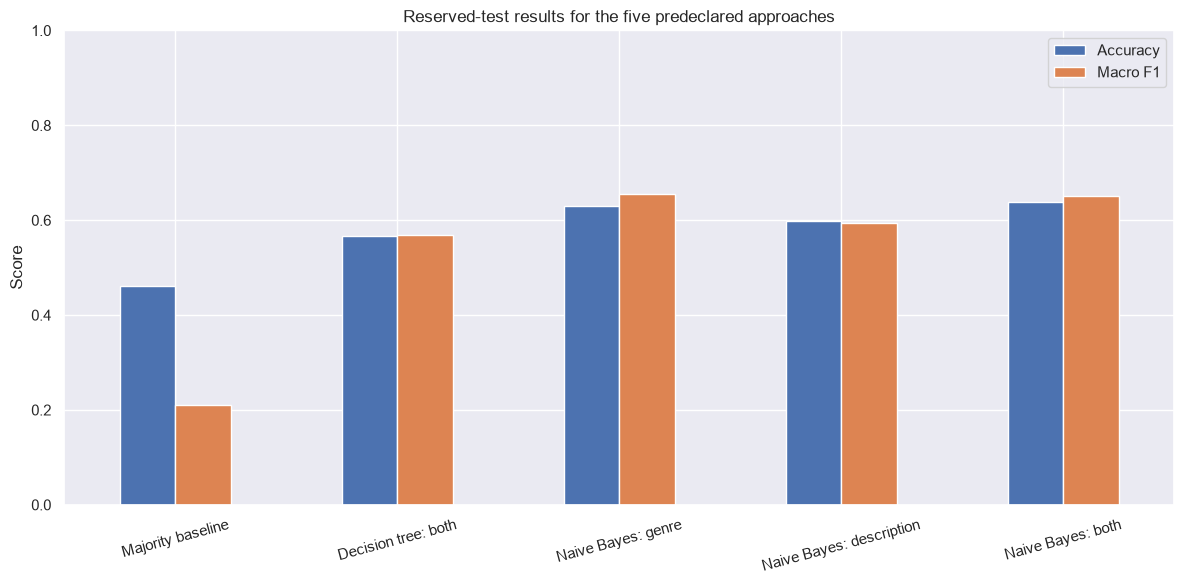

              precision    recall  f1-score   support

        Kids      0.662     0.720     0.689       182
        Teen      0.596     0.597     0.596       759
       Adult      0.673     0.659     0.666       803

    accuracy                          0.638      1744
   macro avg      0.644     0.658     0.651      1744
weighted avg      0.638     0.638     0.638      1744



In [20]:
# M2: comparative bar chart, with all values on the same 0-1 scale
test_results.plot.bar(figsize = (12, 6), ylim = (0, 1), rot = 15)
plt.title("Reserved-test results for the five predeclared approaches")
plt.ylabel("Score")
plt.xlabel("")
plt.tight_layout()
plt.savefig(output_folder / "07_test_comparison.png", dpi = 150)
plt.show()

# EXTENSION E3: per-class evaluation for the validation-selected model
print(classification_report(y_test, selected_test_pred, labels = class_order,
                            digits = 3, zero_division = 0))
class_report = pd.DataFrame(classification_report(
    y_test, selected_test_pred, labels = class_order,
    output_dict = True, zero_division = 0)).transpose()
class_report.to_csv(output_folder / "selected_model_classification_report.csv")

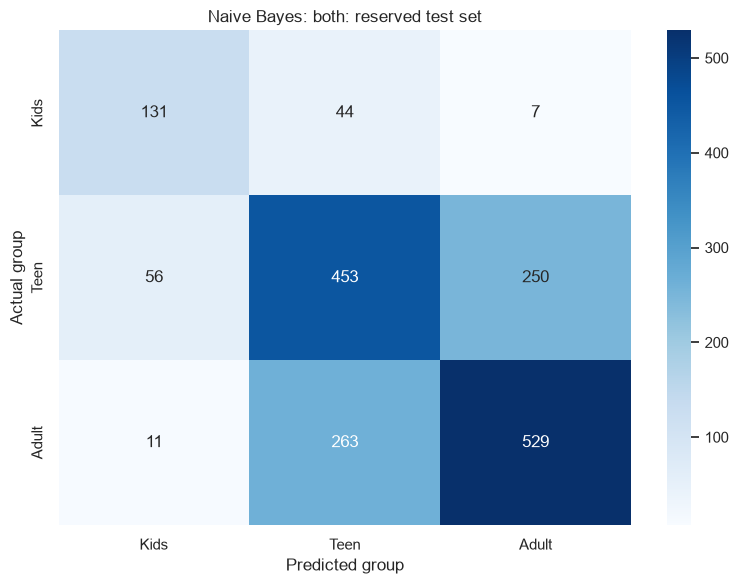

Incorrect predictions : 631


,ShowID,Title,Genre,Description,Rating,RatingGroup,PredictedGroup,Correct
18,s19,Intrusion,Thrillers,After a deadly home invasion at a couple’s new...,TV-14,Teen,Adult,False
21,s22,Resurrection: Ertugrul,"International TV Shows, TV Action & Adventure,...",When a good deed unwittingly endangers his cla...,TV-14,Teen,Adult,False
33,s34,Squid Game,"International TV Shows, TV Dramas, TV Thrillers",Hundreds of cash-strapped players accept a str...,TV-MA,Adult,Teen,False
101,s102,Untold: Breaking Point,"Documentaries, Sports Movies",Under pressure to continue a winning tradition...,TV-MA,Adult,Teen,False
119,s120,Here and There,"Dramas, International Movies, Romantic Movies",After meeting through a heated exchange on soc...,TV-MA,Adult,Teen,False
136,s137,Cold Mountain,"Dramas, Romantic Movies",This drama follows a wounded Civil War soldier...,R,Adult,Teen,False
149,s150,I Got the Hook Up,"Action & Adventure, Comedies",After getting their hands on a misdirected shi...,R,Adult,Teen,False
162,s163,Marshall,Dramas,"This biopic of Thurgood Marshall, the first Bl...",PG-13,Teen,Adult,False


In [21]:
# M4: confusion matrix, with explicit true/predicted class labels
selected_matrix = confusion_matrix(y_test, selected_test_pred, labels = class_order)
f = plt.figure(figsize = (8, 6))
sb.heatmap(selected_matrix, annot = True, fmt = ".0f", cmap = "Blues",
           xticklabels = class_order, yticklabels = class_order)
plt.xlabel("Predicted group")
plt.ylabel("Actual group")
plt.title(selected_model + ": reserved test set")
plt.tight_layout()
plt.savefig(output_folder / "08_confusion_matrix.png", dpi = 150)
plt.show()

# M4: compare actuals and predictions; E4: export
prediction_table = test_data[["ShowID", "Title", "Genre", "Description", "Rating", "RatingGroup"]].copy()
prediction_table["PredictedGroup"] = selected_test_pred
prediction_table["Correct"] = prediction_table["RatingGroup"] == prediction_table["PredictedGroup"]
prediction_table.to_csv(output_folder / "test_predictions.csv", index = False)
print("Incorrect predictions :", (prediction_table["Correct"] == False).sum())
prediction_table[prediction_table["Correct"] == False].head(8)

In [22]:
# P: report observed outcomes without assuming that combined inputs must win
print("Research question: can genre and description predict the project rating group?")
print("Validation-selected model :", selected_model)
print("Its test accuracy :", round(test_results.loc[selected_model, "Accuracy"], 4))
print("Its test Macro F1 :", round(test_results.loc[selected_model, "Macro F1"], 4))
print("Baseline test accuracy :", round(test_results.loc["Majority baseline", "Accuracy"], 4))
print("Baseline test Macro F1 :", round(test_results.loc["Majority baseline", "Macro F1"], 4))
print("Combined NB minus description NB (test Macro F1) :",
      round(test_results.loc["Naive Bayes: both", "Macro F1"] -
            test_results.loc["Naive Bayes: description", "Macro F1"], 4))
print("Combined NB minus genre NB (test Macro F1) :",
      round(test_results.loc["Naive Bayes: both", "Macro F1"] -
            test_results.loc["Naive Bayes: genre", "Macro F1"], 4))

Research question: can genre and description predict the project rating group?
Validation-selected model : Naive Bayes: both
Its test accuracy : 0.6382
Its test Macro F1 : 0.6506
Baseline test accuracy : 0.4604
Baseline test Macro F1 : 0.2102
Combined NB minus description NB (test Macro F1) : 0.0574
Combined NB minus genre NB (test Macro F1) : -0.0055


### What these results establish

The comparison estimates performance on held-out titles from this dataset under one
fixed split and a project-defined three-class mapping. It does not estimate exact
official rating accuracy or prove that genre/text determine the rating.

Review the error rows alongside the confusion matrix. Some synopses may omit
violence, language or other content relevant to a rating. The description model uses
word counts, not word order; its English stop-word list may not suit every synopsis.
Ratings from different systems are combined, the mapping loses detail, and the dataset
may not represent current Netflix content. Test differences are descriptive for this
split; no statistical significance is claimed. Repeated/near-duplicate titles and
franchises can still make generalization harder than this experiment measures.

## 8. Optional M5 investigation: description format and unusual rows

**Course basis: M5 KMeans and LocalOutlierFactor.** Use only training data and three
derived numeric summaries: words, characters and genre count. Standardize using
training means and standard deviations (a pandas arithmetic adaptation of M2 statistics)
so character counts do not dominate distance.

These clusters describe format, not age ratings. LocalOutlierFactor flags relative
unusualness at a preset 5% contamination assumption; it does not verify errors.
No rows are removed and no cluster/anomaly labels are used in the classifiers.

Within Cluster Sum of Squares : 8082.94154082645

Average description format by cluster
         WordCount  CharacterCount  GenreCount
Cluster                                       
0            20.44          128.98        2.25
1            24.82          146.74        3.00
2            24.47          146.15        1.58


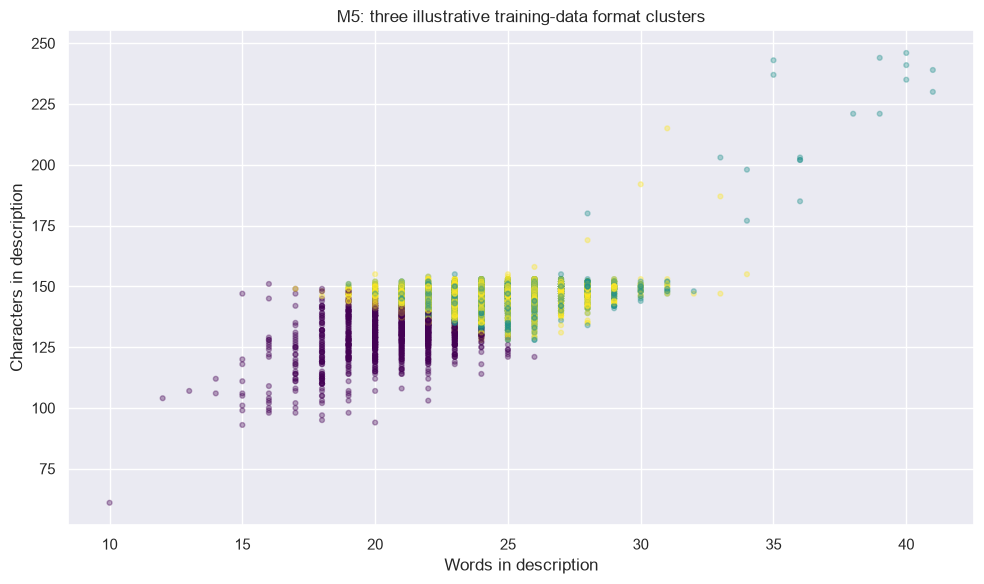

In [23]:
# M5: numeric feature table; P: scale numeric features using M2 statistics
format_data = pd.DataFrame(train_data[["WordCount", "CharacterCount", "GenreCount"]])
format_scaled = (format_data - format_data.mean()) / format_data.std()

from sklearn.cluster import KMeans
num_clust = 3
kmeans = KMeans(n_clusters = num_clust, n_init = 10, random_state = random_seed)
kmeans.fit(format_scaled)
labels = kmeans.predict(format_scaled)

format_labeled = format_data.copy()
format_labeled["Cluster"] = pd.Categorical(labels)
print("Within Cluster Sum of Squares :", kmeans.inertia_)
print("\nAverage description format by cluster")
print(format_labeled.groupby("Cluster", observed = True).mean().round(2))
f = plt.figure(figsize = (10, 6))
plt.scatter(x = "WordCount", y = "CharacterCount", c = labels,
            data = format_labeled, cmap = "viridis", alpha = 0.35, s = 12)
plt.xlabel("Words in description")
plt.ylabel("Characters in description")
plt.title("M5: three illustrative training-data format clusters")
plt.tight_layout()
plt.savefig(output_folder / "09_format_clusters.png", dpi = 150)
plt.show()

In [24]:
# M5: LocalOutlierFactor flags for review only
from sklearn.neighbors import LocalOutlierFactor
# P: avoid a neighborhood filled entirely with identical format measurements
largest_repeated_format = format_data.groupby(
    ["WordCount", "CharacterCount", "GenreCount"]).size().max()
num_neighbors = max(20, int(largest_repeated_format) + 1)
print("Neighbors used after checking repeated formats :", num_neighbors)
cont_fraction = 0.05
lof = LocalOutlierFactor(n_neighbors = num_neighbors, contamination = cont_fraction)
anomaly_labels = lof.fit_predict(format_scaled)
anomaly_review = train_data[["ShowID", "Title", "WordCount", "CharacterCount", "GenreCount"]].copy()
anomaly_review["Anomaly"] = anomaly_labels
print("Rows flagged for review :", (anomaly_labels == -1).sum())
print("Rows automatically removed by M5 :", 0)
anomaly_review.to_csv(output_folder / "training_anomaly_review.csv", index = False)
anomaly_review[anomaly_review["Anomaly"] == -1].head(10)

Neighbors used after checking repeated formats : 43
Rows flagged for review : 255
Rows automatically removed by M5 : 0


,ShowID,Title,WordCount,CharacterCount,GenreCount,Anomaly
6,s7,My Little Pony: A New Generation,25,153,1,-1
10,s11,"Vendetta: Truth, Lies and The Mafia",23,152,3,-1
22,s23,Avvai Shanmughi,25,152,2,-1
40,s41,He-Man and the Masters of the Universe,25,152,2,-1
49,s50,Castle and Castle,22,152,2,-1
67,s68,Saved by the Bell,27,153,2,-1
87,s88,Titipo Titipo,26,131,2,-1
94,s95,Show Dogs,32,147,2,-1
127,s128,A Cinderella Story,27,144,2,-1
132,s133,Brave Animated Series,31,149,3,-1


## 9. Project demonstration

**Course basis: M4 prediction tables and `predict_proba`.**
The first example shows untouched test titles with known actual groups. The second
uses three invented examples so the presenter can edit genre and description live.
For these invented titles, the true group is unknown. The displayed model probability
is an uncalibrated model score, not a guarantee of correctness.

In [25]:
# M4: show actual labels and predictions for fixed test examples
demo_examples = test_data.groupby("RatingGroup", sort = False).head(2)
demo_actual = prediction_table.loc[demo_examples.index,
    ["Title", "Genre", "RatingGroup", "PredictedGroup", "Correct"]]
demo_actual

,Title,Genre,RatingGroup,PredictedGroup,Correct
2,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",Adult,Adult,True
7,Sankofa,"Dramas, Independent Movies, International Movies",Adult,Adult,True
18,Intrusion,Thrillers,Teen,Adult,False
21,Resurrection: Ertugrul,"International TV Shows, TV Action & Adventure,...",Teen,Adult,False
85,Pokémon Master Journeys: The Series,"Anime Series, Kids' TV",Kids,Kids,True
106,Bunk'd,"Kids' TV, TV Comedies",Kids,Kids,True


In [26]:
# P: edit these examples during the demonstration
demo_data = pd.DataFrame({
    "Title" : ["Forest Friends", "The Missing Witness", "Second Chance"],
    "Genre" : ["Kids' TV", "Crime TV Shows, TV Dramas", "Dramas, Romantic Movies"],
    "Description" : [
        "A group of friendly animals learn to share and solve small problems together.",
        "A detective investigates a violent crime and uncovers secrets in a dangerous city.",
        "Two old friends meet again and discover an unexpected chance at love."
    ]
})

# E1: reuse final fitted vocabularies; never fit on demo inputs
demo_genres = final_genre_vectorizer.transform(demo_data["Genre"])
demo_words = final_word_vectorizer.transform(demo_data["Description"])
X_demo_genre = pd.DataFrame(demo_genres.toarray(), columns = final_genre_columns, index = demo_data.index)
X_demo_word = pd.DataFrame(demo_words.toarray(), columns = final_word_columns, index = demo_data.index)
X_demo = pd.concat([X_demo_genre, X_demo_word], axis = 1)

# M4 prediction pattern; P: use the validation-selected approach
if selected_model == "Decision tree: both":
    demo_prediction = final_tree.predict(X_demo)
    demo_score = final_tree.predict_proba(X_demo).max(axis = 1)
elif selected_model == "Naive Bayes: genre":
    demo_prediction = final_nb_genre.predict(X_demo_genre)
    demo_score = final_nb_genre.predict_proba(X_demo_genre).max(axis = 1)
elif selected_model == "Naive Bayes: description":
    demo_prediction = final_nb_word.predict(X_demo_word)
    demo_score = final_nb_word.predict_proba(X_demo_word).max(axis = 1)
elif selected_model == "Naive Bayes: both":
    demo_prediction = final_nb_both.predict(X_demo)
    demo_score = final_nb_both.predict_proba(X_demo).max(axis = 1)
else:
    demo_prediction = np.repeat(final_majority, len(demo_data))
    demo_score = np.repeat(np.nan, len(demo_data))

demo_result = demo_data.copy()
demo_result["PredictedGroup"] = demo_prediction
demo_result["UncalibratedModelScore"] = np.round(demo_score, 3)
demo_result["KnownGenreFeatures"] = np.asarray(demo_genres.sum(axis = 1)).ravel()
demo_result["KnownWordFeatures"] = np.asarray(demo_words.sum(axis = 1)).ravel()
print("Zero known features means that input is not represented by the training vocabulary.")
demo_result.to_csv(output_folder / "demo_predictions.csv", index = False)
demo_result

Zero known features means that input is not represented by the training vocabulary.


,Title,Genre,Description,PredictedGroup,UncalibratedModelScore,KnownGenreFeatures,KnownWordFeatures
0,Forest Friends,Kids' TV,A group of friendly animals learn to share and...,Kids,0.998,1,8
1,The Missing Witness,"Crime TV Shows, TV Dramas",A detective investigates a violent crime and u...,Adult,0.997,2,8
2,Second Chance,"Dramas, Romantic Movies",Two old friends meet again and discover an une...,Teen,0.847,2,7


## 10. Findings, slides and submission

The companion slide deck uses the actual saved tables. Suggested eight-minute flow:

| Topic | Time | Evidence |
|---|---:|---|
| Question and three variables | 45 s | Data dictionary and input/target distinction |
| Cleaning and project rating mapping | 60 s | Cleaning summary and exclusions |
| Training patterns | 75 s | Genre proportions and description-length plots |
| Fair split and models | 75 s | Group separation and validation comparison |
| Test findings and errors | 105 s | Results table, confusion matrix, error rows |
| Demonstration | 60 s | Edit the three demo inputs above |
| Limitations, extensions and contributions | 60 s | M1–M5 source map and team record |

**Rehearsal:** run the notebook before presenting, open the result plots, and use the
demo cells for live input. Saved demo outputs are the backup.

**Team contributions:** record each person's actual contribution before submission;
no names or work allocations have been invented.

**Final checks:** restart the kernel and Run All; verify relative paths; include this
notebook, original CSV, generated outputs, slides, requirements and references in
the submission ZIP. Check the latest course brief for the deadline; the repository
README currently states 13 November 2026 at 23:59.

The automated work is complete when all cells run and outputs agree. Team review,
authorship/contribution details, rehearsal and NTULearn submission remain human tasks.

In [27]:
# EXTENSION E4: store exact environment and presentation data for this run
requirements = {
    "numpy" : np.__version__, "pandas" : pd.__version__,
    "matplotlib" : matplotlib.__version__, "seaborn" : sb.__version__,
    "scikit-learn" : sklearn.__version__
}
with open(output_folder / "analysis_requirements.txt", "w", encoding = "utf-8") as file:
    for package in requirements:
        file.write(package + "==" + requirements[package] + "\n")

presentation_data = {
    "raw_rows" : len(netflix_data), "clean_rows" : len(netflix_clean),
    "excluded_counts" : excluded_data["ExclusionReason"].value_counts().to_dict(),
    "group_counts" : netflix_clean["RatingGroup"].value_counts().to_dict(),
    "train_rows" : len(train_data), "valid_rows" : len(valid_data), "test_rows" : len(test_data),
    "repeated_descriptions" : int(netflix_clean.duplicated("DescriptionKey").sum()),
    "selected_model" : selected_model,
    "validation_results" : validation_results.reset_index().to_dict(orient = "records"),
    "test_results" : test_results.reset_index().to_dict(orient = "records"),
    "confusion_matrix" : selected_matrix.tolist(), "class_order" : class_order,
    "classification_report" : classification_report(y_test, selected_test_pred,
        labels = class_order, output_dict = True, zero_division = 0),
    "genre_percentages" : genre_percent.round(2).reset_index().to_dict(orient = "records"),
    "demo_predictions" : demo_result[["Title", "PredictedGroup"]].to_dict(orient = "records"),
    "training_word_mean" : float(train_data["WordCount"].mean()),
    "genre_features" : len(final_genre_columns), "word_features" : len(final_word_columns)
}
with open(output_folder / "presentation_data.json", "w", encoding = "utf-8") as file:
    json.dump(presentation_data, file, indent = 2)
print("Saved cleaned data, splits, figures, results and demo outputs in", output_folder)

Saved cleaned data, splits, figures, results and demo outputs in course_project_outputs


### References and external additions

- Supplied M1, M2, M4 and M5 notebooks: course code patterns listed at the beginning.
- [Project README](https://github.com/kyvenlim72-lang/IE1005-Mini-Project): research question and deliverables.
- [Dataset source](https://www.kaggle.com/datasets/shivamb/netflix-shows/data): Netflix Movies and TV Shows, as linked in the README.
- E1: [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html).
- E2: [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html).
- E3: [f1_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) and [classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).
- E4: [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), [pandas CSV export](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html), [Matplotlib figure export](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html) and [pathlib](https://docs.python.org/3/library/pathlib.html).

The code's new text/model/metric features are explicitly marked E1–E3. P identifies
new project logic. E4 covers saving and checks. Creating the companion PowerPoint
uses presentation-authoring tools outside the M1–M5 material; that tooling is not
part of the analysis or the claimed course-code reuse.